# Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Question 1

In [2]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)


Epoch 1/10, Loss: 0.9769052432775498
Epoch 2/10, Loss: 0.9498113926649093
Epoch 3/10, Loss: 0.9360854610204696
Epoch 4/10, Loss: 0.9275407440662384
Epoch 5/10, Loss: 0.9216015691161156
Epoch 6/10, Loss: 0.9171953783631325
Epoch 7/10, Loss: 0.9137822569608688
Epoch 8/10, Loss: 0.9110551126599312
Epoch 9/10, Loss: 0.9088255043625831
Epoch 10/10, Loss: 0.9069729180335998


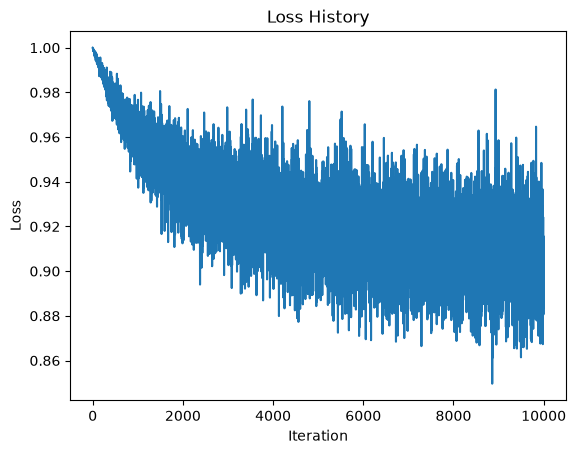

Training accuracy: 30.98%
Test accuracy: 31.03%


In [3]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std
b = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss calculation (MSE with regularization)
        loss = (
            (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2)
            + reg * torch.sum(w ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)

        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


Epoch 1/10, Loss: 2.2242247643470763
Epoch 2/10, Loss: 2.1044143708944323
Epoch 3/10, Loss: 2.056496719479561
Epoch 4/10, Loss: 2.0245656824111937
Epoch 5/10, Loss: 2.0011795505285264
Epoch 6/10, Loss: 1.9832485226392746
Epoch 7/10, Loss: 1.9690350716114045
Epoch 8/10, Loss: 1.9575800668001175
Epoch 9/10, Loss: 1.948170693874359
Epoch 10/10, Loss: 1.9403175835609436


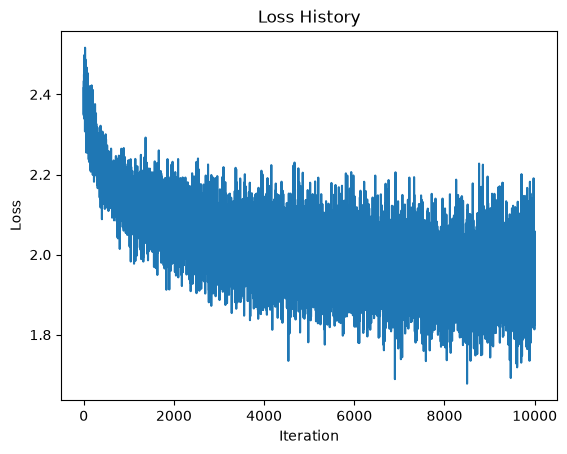

Training accuracy: 33.89%
Test accuracy: 34.27%


In [4]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Hidden layer size
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * (1 / Din**0.5)
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * (1 / H**0.5)
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-3
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_train.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_pred = hidden1.mm(w2) + b2

        # Loss calculation (cross-entropy with regularization)
        loss = (
            nn.functional.cross_entropy(y_pred, labels)
            + reg * torch.sum(w1 ** 2)
            + reg * torch.sum(w2 ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1)
        dy_pred[torch.arange(Ntr), labels] -= 1
        dy_pred /= Ntr

        dw2 = hidden1.t().mm(dy_pred) + 2 * reg * w2
        db2 = dy_pred.sum(dim=0)

        dhidden = dy_pred.mm(w2.t()) * hidden1 * (1 - hidden1)

        dw1 = x_train.t().mm(dhidden) + 2 * reg * w1
        db1 = dhidden.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_train.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_train_pred = hidden1.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_test.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_test_pred = hidden1.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


With the same parameters the model with the hidden layer performs much worse. This is due to much slower learning rate implemented. Increasing the learning rate gave the model same performance as the original model. 

# Question 2

In [2]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

batch_size = 50

trainset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    '0', '1', '2', '3', '4',
    '5', '6', '7', '8', '9'
)


In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    num_correct, num_images = 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        n = labels.size(0)
        running_loss += loss.item() * n
        num_correct += (logits.argmax(dim=1) == labels).sum().item()
        num_images += n
    return running_loss / num_images, 100.0 * num_correct / num_images


@torch.no_grad()
def evaluate(model, loader, criterion, return_confusion=False):
    model.eval()  # disables dropout; batch norm uses running statistics
    running_loss = 0.0
    num_correct, num_images = 0, 0
    cm = np.zeros((10, 10), dtype=np.int64) if return_confusion else None
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        loss = criterion(logits, labels)
        predicted = logits.argmax(dim=1)

        n = labels.size(0)
        running_loss += loss.item() * n
        num_correct += (predicted == labels).sum().item()
        num_images += n
        if return_confusion:
            flat_indices = labels * 10 + predicted
            cm += torch.bincount(flat_indices, minlength=100).view(10, 10).cpu().numpy()

    return running_loss / num_images, 100.0 * num_correct / num_images, cm

In [4]:
def train(model, name):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [], "train_acc": [],
        "test_loss": [], "test_acc": []
    }

    for epoch in range(10):
        tr_loss, tr_acc = train_one_epoch(
            model, trainloader, optimizer, criterion
        )
        te_loss, te_acc, _ = evaluate(
            model, testloader, criterion
        )

        for key, value in zip(history, [tr_loss, tr_acc, te_loss, te_acc]):
            history[key].append(value)

        print(f"{name} | Epoch {epoch+1}/10 | "
                f"Train Acc: {tr_acc:.2f}% | Test Acc: {te_acc:.2f}% | "
                f"Train Loss: {tr_loss:.4f} | Test Loss: {te_loss:.4f}")

    results[name] = history
    _, _, confusions[name] = evaluate(
        model, testloader, criterion, return_confusion=True
    )

    print(f"\n{name} Final Results:")
    print(f"Training Accuracy: {tr_acc:.2f}%")
    print(f"Test Accuracy: {te_acc:.2f}%\n")

    return history, confusions[name]

In [5]:
results = {}
confusions = {}

## LeNet-5

In [6]:
class LeNet5(nn.Module):
    """Classic LeNet-5 layout for 32 x 32 grayscale input."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),     # 32 -> 28
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2),         # 28 -> 14
            nn.Conv2d(6, 16, kernel_size=5),    # 14 -> 10
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2),         # 10 -> 5
            nn.Conv2d(16, 120, kernel_size=5),  # 5 -> 1
            nn.Tanh(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10),                  # logits (no softmax)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [10]:
lenet = LeNet5()
lenet_history, lenet_confusion = train(lenet, "lenet")

lenet | Epoch 1/10 | Train Acc: 93.63% | Test Acc: 97.83% | Train Loss: 0.2212 | Test Loss: 0.0746
lenet | Epoch 2/10 | Train Acc: 97.90% | Test Acc: 98.40% | Train Loss: 0.0687 | Test Loss: 0.0489
lenet | Epoch 3/10 | Train Acc: 98.47% | Test Acc: 98.47% | Train Loss: 0.0500 | Test Loss: 0.0486
lenet | Epoch 4/10 | Train Acc: 98.78% | Test Acc: 98.77% | Train Loss: 0.0384 | Test Loss: 0.0369
lenet | Epoch 5/10 | Train Acc: 98.96% | Test Acc: 98.57% | Train Loss: 0.0328 | Test Loss: 0.0473
lenet | Epoch 6/10 | Train Acc: 99.19% | Test Acc: 98.73% | Train Loss: 0.0264 | Test Loss: 0.0379
lenet | Epoch 7/10 | Train Acc: 99.26% | Test Acc: 98.91% | Train Loss: 0.0228 | Test Loss: 0.0339
lenet | Epoch 8/10 | Train Acc: 99.36% | Test Acc: 98.71% | Train Loss: 0.0194 | Test Loss: 0.0372
lenet | Epoch 9/10 | Train Acc: 99.43% | Test Acc: 98.72% | Train Loss: 0.0182 | Test Loss: 0.0379
lenet | Epoch 10/10 | Train Acc: 99.51% | Test Acc: 98.57% | Train Loss: 0.0148 | Test Loss: 0.0493

lenet Fi

## Modern CNN

In [8]:
class ModernSmallCNN(nn.Module):
    """Exactly three conv layers, each with batch norm and pooling."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 32 -> 16

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 16 -> 8

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 8 -> 4
            nn.Dropout2d(p=0.15),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(p=0.35),
            nn.Linear(64, 10),                    # logits
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [11]:
modern_cnn = ModernSmallCNN()
modern_cnn_history, modern_cnn_confusion = train(modern_cnn, "modern_cnn")

modern_cnn | Epoch 1/10 | Train Acc: 93.06% | Test Acc: 98.34% | Train Loss: 0.2349 | Test Loss: 0.0501
modern_cnn | Epoch 2/10 | Train Acc: 97.12% | Test Acc: 98.97% | Train Loss: 0.0955 | Test Loss: 0.0287
modern_cnn | Epoch 3/10 | Train Acc: 97.69% | Test Acc: 99.04% | Train Loss: 0.0787 | Test Loss: 0.0317
modern_cnn | Epoch 4/10 | Train Acc: 98.03% | Test Acc: 99.02% | Train Loss: 0.0643 | Test Loss: 0.0332
modern_cnn | Epoch 5/10 | Train Acc: 98.34% | Test Acc: 98.81% | Train Loss: 0.0566 | Test Loss: 0.0326
modern_cnn | Epoch 6/10 | Train Acc: 98.43% | Test Acc: 99.10% | Train Loss: 0.0524 | Test Loss: 0.0302
modern_cnn | Epoch 7/10 | Train Acc: 98.58% | Test Acc: 99.01% | Train Loss: 0.0475 | Test Loss: 0.0360
modern_cnn | Epoch 8/10 | Train Acc: 98.75% | Test Acc: 99.27% | Train Loss: 0.0418 | Test Loss: 0.0260
modern_cnn | Epoch 9/10 | Train Acc: 98.86% | Test Acc: 99.22% | Train Loss: 0.0381 | Test Loss: 0.0255
modern_cnn | Epoch 10/10 | Train Acc: 98.99% | Test Acc: 99.21% 

In [12]:
modern_cnn_history

{'train_loss': [0.23492630718353516,
  0.09550078738771844,
  0.07867996802708754,
  0.06430887625533312,
  0.05660619335588611,
  0.05244635781928082,
  0.04748523519097944,
  0.04179797931739207,
  0.03807314140061256,
  0.033061864933770266],
 'train_acc': [93.05666666666667,
  97.12166666666667,
  97.69333333333333,
  98.035,
  98.33666666666667,
  98.42666666666666,
  98.585,
  98.74833333333333,
  98.85666666666667,
  98.98833333333333],
 'test_loss': [0.05012496675739385,
  0.028742213781224563,
  0.031694908356666926,
  0.033241669180277995,
  0.03259303169062605,
  0.03016453395628048,
  0.03596200720825891,
  0.026020779169918882,
  0.025524956020835248,
  0.02859965632333661],
 'test_acc': [98.34,
  98.97,
  99.04,
  99.02,
  98.81,
  99.1,
  99.01,
  99.27,
  99.22,
  99.21]}

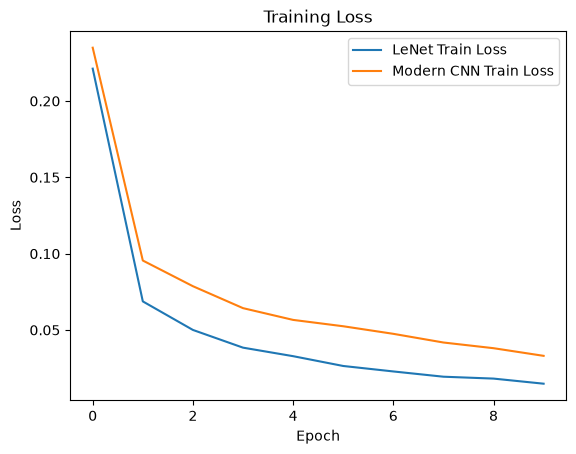

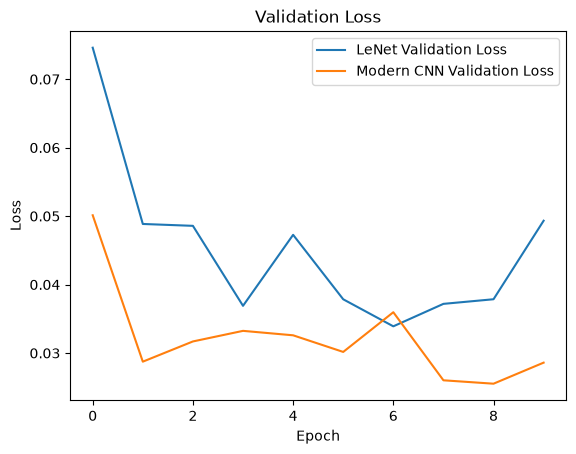

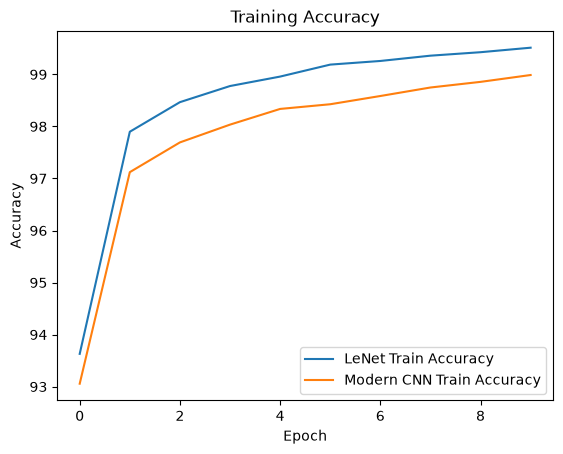

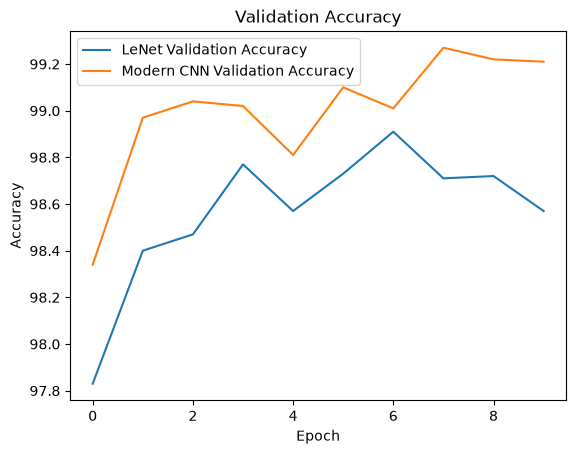

In [16]:
plt.plot(lenet_history["train_loss"], label="LeNet Train Loss")
plt.plot(modern_cnn_history["train_loss"], label="Modern CNN Train Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.show()

plt.plot(lenet_history["test_loss"], label="LeNet Validation Loss")
plt.plot(modern_cnn_history["test_loss"], label="Modern CNN Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss")
plt.legend()
plt.show()

plt.plot(lenet_history["train_acc"], label="LeNet Train Accuracy")
plt.plot(modern_cnn_history["train_acc"], label="Modern CNN Train Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.show()

plt.plot(lenet_history["test_acc"], label="LeNet Validation Accuracy")
plt.plot(modern_cnn_history["test_acc"], label="Modern CNN Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.show()



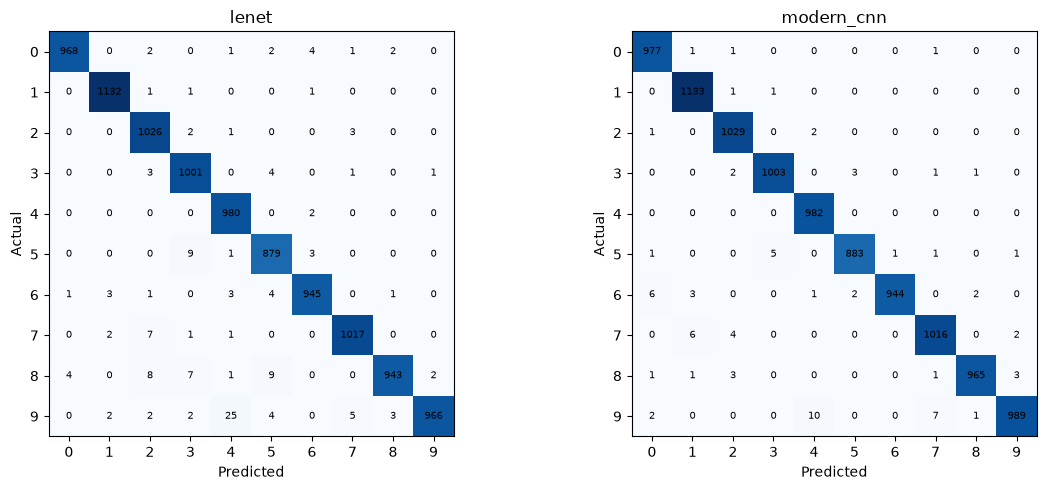

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, cm) in zip(axes, confusions.items()):
    ax.imshow(cm, cmap="Blues")

    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center", fontsize=7)

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

plt.tight_layout()
plt.show()